# So sánh dự báo PM2.5
Notebook chỉ đọc báo cáo đã xuất. Chọn model bằng validation MAE trước khi đọc test, xem README để chạy CLI. Chưa có báo cáo thì chạy các bước dữ liệu, train và evaluation trước.
MAE/RMSE: µg/m³, SMAPE: %, R²: không đơn vị, giá trị không xác định giữ trống.

## Đường PM2.5 thực tế và dự báo theo thời gian
Biểu đồ kiểu mẫu: đường thực tế xanh liền, các model nét đứt, mặc định 14 ngày đầu của validation. Hiện có Conv1D-GRU seed 42. Khi có kết quả evaluation của LSTM/SE-LSTM, thêm chúng vào MODEL_RUNS để vẽ chung.

Mỗi timestamp lấy đúng dự báo trước HORIZON_HOURS giờ, không ghép phẳng 24 đầu ra chồng lấn. Giờ thiếu được để đứt nét, không nội suy để làm đẹp hình. Chỉ đọc predictions.npz đã lưu, không chạy lại model. Chỉ chuyển SPLIT sang test khi đã có evaluation test hợp lệ.

Có thể đổi HORIZON_HOURS thành 1/6/12/24, WINDOW_DAYS hoặc START_TIME, ví dụ một ngày ISO có timezone. START_TIME=None lấy mốc target đầu tiên. Trục thời gian dùng UTC, dữ liệu PM2.5 theo µg/m³.

In [85]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "configs/common.yaml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from HN_PM25_forecasting")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.plots import load_forecast_timeline, plot_forecast_timeline

# 42, 52, 62
SEED = 62  # Có thể chọn 42, 52 hoặc 62
SPLIT = "validation"
HORIZON_HOURS = 1
WINDOW_DAYS = 14
START_TIME = None
MODEL_RUNS = {
    # "conv1d_gru": "conv1d-gru-cpu-v1",
    #"lstm": "lstm-cpu-v1",
    "se_lstm": "se-lstm-mse-cpu-v1",
}
OUTPUT_PATH = (ROOT / "reports/figures/models_timeline" / SPLIT
               / f"forecast_vs_actual_h{HORIZON_HOURS}_seed{SEED}.png")


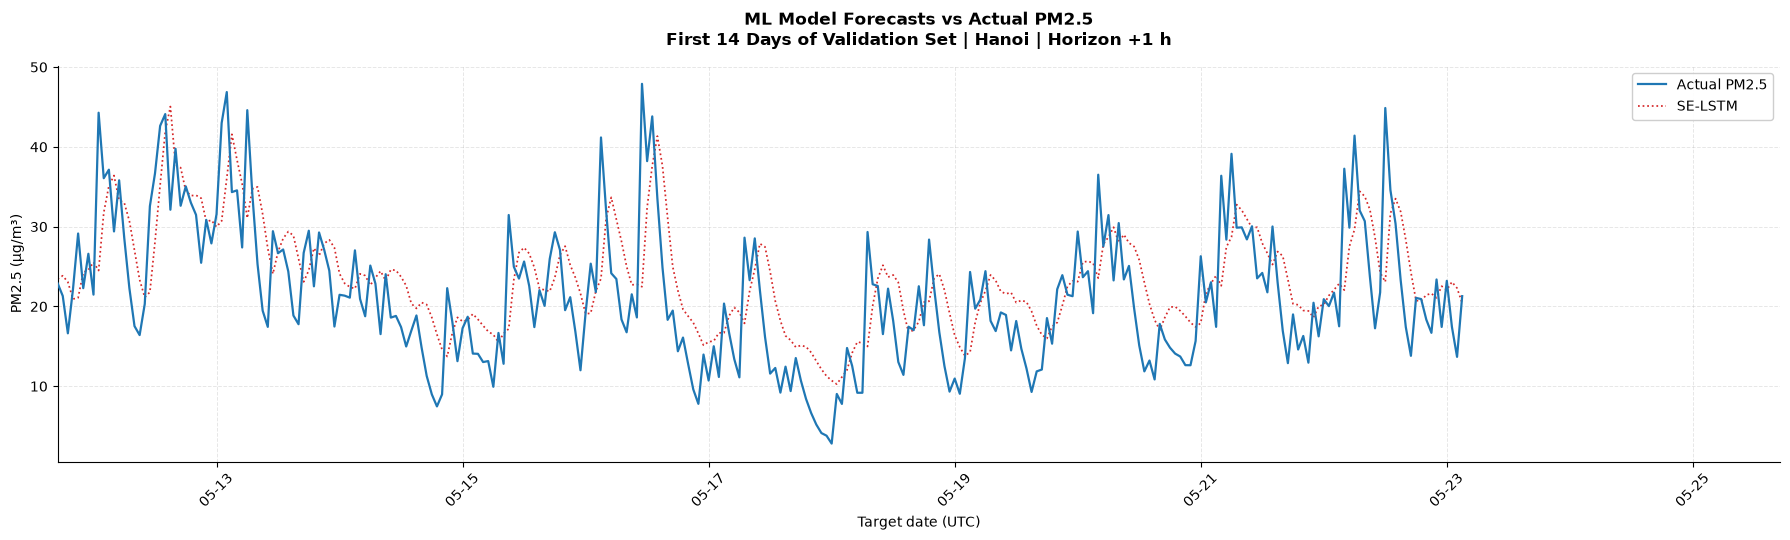

Saved figure: c:\MCU\ESP32\ESP32\ESP32_node\HN_PM25_forecasting\reports\figures\models_timeline\validation\forecast_vs_actual_h1_seed62.png
Split: validation, seed: 62, forecast lead: +1 hour(s)


,actual,se_lstm
target_time,,
2025-05-11 17:00:00+00:00,22.90,23.431633
2025-05-11 18:00:00+00:00,21.32,23.845940
2025-05-11 19:00:00+00:00,16.63,23.054071
2025-05-11 20:00:00+00:00,22.17,20.929464
2025-05-11 21:00:00+00:00,29.14,21.089354
2025-05-11 22:00:00+00:00,22.29,24.268261
2025-05-11 23:00:00+00:00,26.60,24.574192
2025-05-12 00:00:00+00:00,21.48,25.545856
2025-05-12 01:00:00+00:00,44.28,24.498959


In [86]:
evaluation_dirs = {
    model: ROOT / "runs" / model / run_id / f"seed_{SEED}" / "evaluation" / SPLIT
    for model, run_id in MODEL_RUNS.items()
}
missing = [str(folder) for folder in evaluation_dirs.values()
           if not (folder / "predictions.npz").is_file()
           or not (folder / "metrics.json").is_file()]
if missing:
    print("Run scripts.evaluate first for these evaluation folders:")
    print("\n".join(missing))
else:
    timeline = load_forecast_timeline(evaluation_dirs, horizon_hours=HORIZON_HOURS)
    fig = plot_forecast_timeline(
        timeline, split=SPLIT, horizon_hours=HORIZON_HOURS,
        window_days=WINDOW_DAYS, start=START_TIME, output_path=OUTPUT_PATH,
    )
    plt.show()
    print(f"Saved figure: {OUTPUT_PATH}")
    print(f"Split: {SPLIT}, seed: {SEED}, forecast lead: +{HORIZON_HOURS} hour(s)")
    display(timeline.head(24))


In [87]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd() / 'configs/common.yaml').exists() else Path.cwd().parent
RUN_ID = 'baseline-v1'
SPLIT = 'validation'
tables = ROOT / 'reports/tables' / f'models_{RUN_ID}'
summary = tables / SPLIT / 'summary.csv'
if not summary.exists():
    print(f'Chưa có báo cáo: {summary}, xem README để chạy pipeline.')
else:
    display(pd.read_csv(summary))
    detail = pd.read_csv(tables / SPLIT / 'per_horizon.csv')
    display(detail[detail.horizon.isin([1, 6, 12, 24])])
    selection = tables / 'selection.json'
    if selection.exists():
        locked = json.loads(selection.read_text(encoding='utf-8'))
        print('Primary model từ validation:', locked['primary_model'])


Chưa có báo cáo: c:\MCU\ESP32\ESP32\ESP32_node\HN_PM25_forecasting\reports\tables\models_baseline-v1\validation\summary.csv, xem README để chạy pipeline.


In [88]:
figures = ROOT / 'reports/figures' / f'models_{RUN_ID}' / SPLIT
for name in ('horizon_metrics.png', 'learning_and_forecast.png'):
    image = figures / name
    if image.exists():
        display(Image(filename=str(image)))


In [89]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

folder = (
    root / "/runs/se_lstm/se-lstm-mse-cpu-v1"
    / "seed_62/evaluation/validation"
)

with np.load(folder / "predictions.npz") as data:
    i = 0  # Cửa sổ dự báo đầu tiên, đổi i để xem cửa sổ khác
    comparison = pd.DataFrame({
        "time": pd.to_datetime(data["target_times"][i], unit="ns", utc=True),
        "actual": data["y_true_raw"][i],
        "predicted": data["y_pred_raw"][i],
    })

ax = comparison.set_index("time").plot(figsize=(12, 4), marker="o")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Conv1D-GRU: thực tế và dự báo 24 giờ")
plt.tight_layout()
plt.show()

display(comparison)

FileNotFoundError: [Errno 2] No such file or directory: 'c:\\runs\\se_lstm\\se-lstm-mse-cpu-v1\\seed_62\\evaluation\\validation\\predictions.npz'